In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))   # make `src` importable when running from notebooks/
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_sample_weight
from src.config import *
from src.utils import *
from src.experiments import PARAM_DISTS, multiclass_metrics
from src.imbalance import METHODS, resample, cv_method, fit_with_method

# Challenge 2 - Handling the class imbalance
Only 7% of the training images are scc. A model trained as is learns that predicting scc is rarely worth it, so it misses most of them.

This notebook answers one question: **which way of handling the imbalance works best?**
To compare only the strategies, the classifier is always the same: the best model of `multiclass-baseline.ipynb` with its hyperparameters fixed.

Structure:
1. The data and the base model.
2. The 4 strategies, one by one, showing what each one does to the training data.
3. Comparison with 5-fold CV on train.
4. Evaluation on the validation set and choice of the best strategy.

The code of the strategies is in `src/imbalance.py`.

## 1. Data and base model

In [2]:
train, val = pd.read_csv(MULTI_FEATURES_TRAIN_CSV), pd.read_csv(MULTI_FEATURES_VAL_CSV)
bundle = joblib.load(MODELS_DIR / "multi_baseline_v1.joblib")
feature_cols = bundle["feature_cols"]
X, y = train[feature_cols].values, train["label"].values
X_val, y_val = val[feature_cols].values, val["label"].values
names = list(MULTI_CLASS_NAMES.values())

base_model = bundle["model"]
tuned = PARAM_DISTS.get(bundle["model_name"], {})                     # only SVM, XGBoost and CatBoost were tuned
print("Base model:", bundle["model_name"])
print("Hyperparameters:", {k: round(float(base_model.get_params()[k]), 4) for k in tuned} or "library defaults")

counts = pd.Series(np.bincount(y), index=names)
print("\nTraining images per class:", counts.to_dict())

Base model: SVM (RBF)
Hyperparameters: {'svc__C': 30.6346, 'svc__gamma': 0.0012}

Training images per class: {'mel': 2713, 'bcc': 1993, 'scc': 376}


## 2. The 4 strategies
Each strategy changes **what the model sees during training**. The table at the end of this section summarises it.

### 2.1 `none`: train as is
The model sees the 5082 images, each one with weight 1. scc has 7% of the total weight.

In [3]:
effect = {"none": pd.DataFrame({"images": counts, "weight per image": 1.0})}
effect["none"]

,images,weight per image
mel,2713,1.0
bcc,1993,1.0
scc,376,1.0


### 2.2 `weights`: balanced class weights
Same images, but each one is weighted by **n_total / (n_classes x n_images_of_its_class)**.
The weight multiplies the error of that image in the training loss, so a mistake on an scc costs ~7 times more than a mistake on a mel.
With these weights the **total weight of each class is the same** (5082 / 3 = 1694).

In [4]:
w = compute_sample_weight("balanced", y)            # one weight per image
effect["weights"] = pd.DataFrame({"images": counts, "weight per image": [w[y == c][0] for c in range(3)]}, index=names)
effect["weights"]["total weight"] = effect["weights"]["images"] * effect["weights"]["weight per image"]
effect["weights"].round(3)

,images,weight per image,total weight
mel,2713,0.624,1694.0
bcc,1993,0.850,1694.0
scc,376,4.505,1694.0


### 2.3 `undersample`: remove images of the big classes
Keep a random selection of **376 images of every class** (the size of scc). The model trains with 3 x 376 = 1128 images,
so the classes are balanced, but ~78% of the training images are thrown away.

In [5]:
X_under, y_under = resample(X, y, "undersample")
effect["undersample"] = pd.DataFrame({"images": np.bincount(y_under), "weight per image": 1.0}, index=names)
effect["undersample"]

,images,weight per image
mel,376,1.0
bcc,376,1.0
scc,376,1.0


### 2.4 `oversample`: duplicate images of the small classes
Copy random images of bcc and scc (with repetition) until **every class has 2713 images** (the size of mel).
No information is lost, but the same scc image appears ~7 times, which can make the model memorise them.

MODIFY THIS: Oversampling cannot be done with just copies of the same images, it needs to introduce some variety, otherwise you are not really forcing the model to learn anything new, and additionally you will have an overfitting model. Try random rotations (between +90º and -90º), flipping in X and Y axis, adding gaussian noise, blurring a bit the images (apply just one time a mild gaussian blurring) and change the illumination (try doing one slightly darker and one slightly brighter than the original). It is not necessary to reach a ful balanced dataset!!

In [6]:
X_over, y_over = resample(X, y, "oversample")
effect["oversample"] = pd.DataFrame({"images": np.bincount(y_over), "weight per image": 1.0}, index=names)
unique_scc = len(np.unique(X_over[y_over == 2], axis=0))
print(f"scc images after oversampling: {np.bincount(y_over)[2]}, of which different: {unique_scc}")
# (375 and not 376: two scc images of train have exactly the same features, probably the same picture twice)
effect["oversample"]

scc images after oversampling: 2713, of which different: 375


,images,weight per image
mel,2713,1.0
bcc,2713,1.0
scc,2713,1.0


### Summary: what the model sees with each strategy

In [7]:
summary_effect = pd.DataFrame({
    m: {**{f"images {n}": int(effect[m].loc[n, "images"]) for n in names},
        **{f"% of total weight {n}": round(100 * (effect[m]["images"] * effect[m]["weight per image"]).loc[n]
                                            / (effect[m]["images"] * effect[m]["weight per image"]).sum(), 1) for n in names}}
    for m in METHODS}).T
summary_effect.astype({f"images {n}": int for n in names})

,images mel,images bcc,images scc,% of total weight mel,% of total weight bcc,% of total weight scc
none,2713,1993,376,53.4,39.2,7.4
weights,2713,1993,376,33.3,33.3,33.3
undersample,376,376,376,33.3,33.3,33.3
oversample,2713,2713,2713,33.3,33.3,33.3


## 3. Comparison with 5-fold CV on train
For each strategy and each fold, the strategy is applied **only to the 4 training parts** of the fold;
the 5th part keeps the real proportions (53 / 39 / 7%) and is used to score it. Result: mean ± std of the 5 folds.

In [8]:
cv_results = pd.DataFrame([{"method": m, **cv_method(base_model, X, y, m)} for m in METHODS])
cv_results.to_csv(RESULTS_DIR / "multi_cv_imbalance.csv", index=False)

shown = ["balanced_accuracy", "kappa", "accuracy"] + [f"recall_{n}" for n in names]
view = cv_results[["method"]].copy()
for m in shown:
    view[m] = cv_results[m].map("{:.3f}".format) + " ± " + cv_results[f"{m}_std"].map("{:.3f}".format)
view.rename(columns={f"recall_{n}": f"acc. {n}" for n in names})

,method,balanced_accuracy,kappa,accuracy,acc. mel,acc. bcc,acc. scc
0,none,0.645 ± 0.010,0.686 ± 0.010,0.831 ± 0.006,0.896 ± 0.013,0.866 ± 0.011,0.173 ± 0.039
1,weights,0.734 ± 0.014,0.661 ± 0.010,0.805 ± 0.007,0.857 ± 0.023,0.780 ± 0.012,0.564 ± 0.047
2,undersample,0.692 ± 0.013,0.529 ± 0.017,0.714 ± 0.012,0.761 ± 0.025,0.660 ± 0.015,0.654 ± 0.041
3,oversample,0.724 ± 0.011,0.653 ± 0.016,0.801 ± 0.010,0.861 ± 0.021,0.769 ± 0.012,0.543 ± 0.045


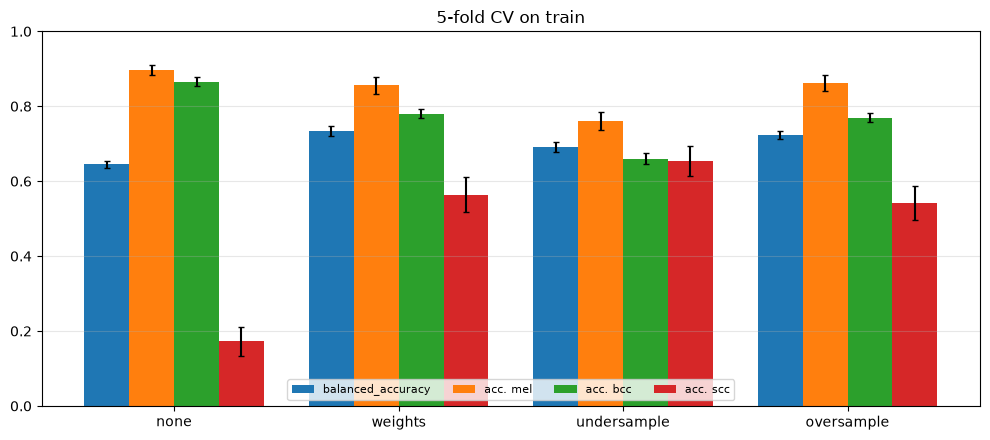

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(METHODS))
bars = ["balanced_accuracy"] + [f"recall_{n}" for n in names]
for i, metric in enumerate(bars):
    ax.bar(x + (i - 1.5) * 0.2, cv_results[metric], width=0.2, yerr=cv_results[f"{metric}_std"], capsize=2,
           label=metric.replace("recall_", "acc. "))
ax.set_xticks(x, METHODS)
ax.set_ylim(0, 1)
ax.set_title("5-fold CV on train")
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=4, fontsize=8, loc="lower center")
plt.tight_layout()
plt.show()

## 4. Evaluation on the validation set
Each strategy is applied to the whole train set, and the model is evaluated once on validation.
The best strategy is chosen by **CV balanced accuracy** (never by the validation score).

In [10]:
fitted = {m: fit_with_method(base_model, X, y, m) for m in METHODS}          # method -> model trained on all of train
predictions = {m: model.predict(X_val) for m, model in fitted.items()}

val_results = pd.DataFrame([{"method": m, **multiclass_metrics(y_val, y_pred)} for m, y_pred in predictions.items()])
val_results.to_csv(RESULTS_DIR / "multi_val_imbalance.csv", index=False)
(val_results.set_index("method")[shown]
 .rename(columns={f"recall_{n}": f"acc. {n}" for n in names}).round(3))

,balanced_accuracy,kappa,accuracy,acc. mel,acc. bcc,acc. scc
method,,,,,,
none,0.673,0.705,0.841,0.895,0.880,0.245
weights,0.750,0.670,0.811,0.858,0.785,0.606
undersample,0.699,0.526,0.710,0.740,0.675,0.681
oversample,0.725,0.658,0.806,0.858,0.785,0.532


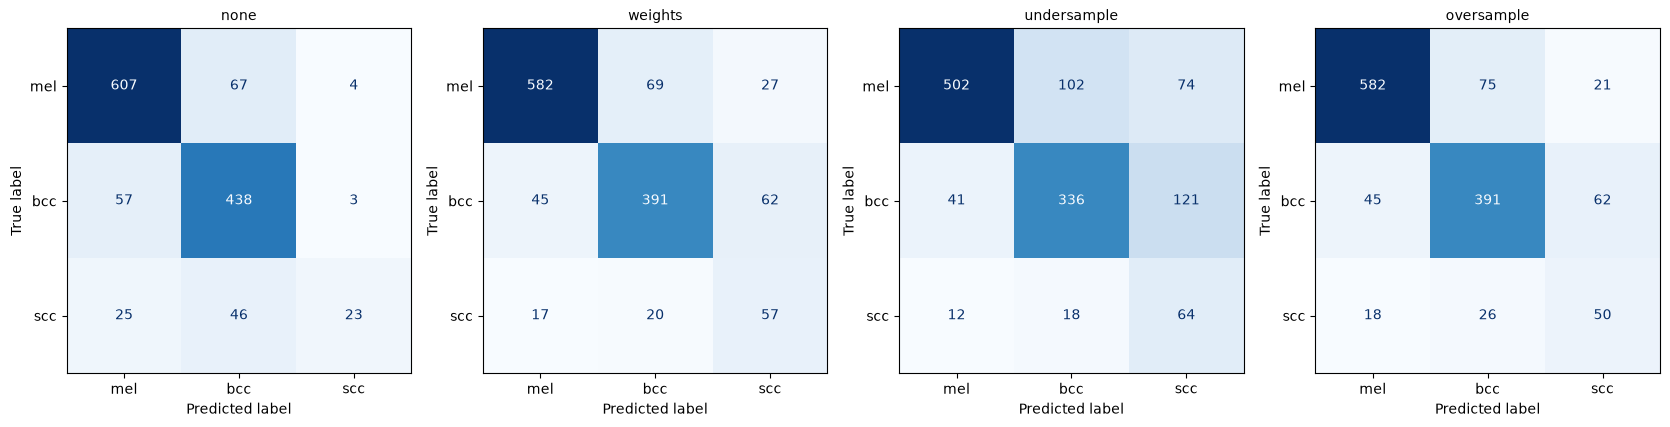

In [11]:
fig, axes = plt.subplots(1, len(METHODS), figsize=(4.2 * len(METHODS), 4.2))
for ax, m in zip(axes, METHODS):
    plot_confusion(ax, y_val, predictions[m], m, class_names=names)
plt.tight_layout()
plt.show()

In [12]:
best = cv_results.loc[cv_results["balanced_accuracy"].idxmax(), "method"]
best_val = val_results.set_index("method").loc[best]
print(f"Best strategy (highest CV balanced accuracy): {best}")
print(f"  Validation balanced accuracy: {best_val['balanced_accuracy']:.3f}")
print(f"  Validation kappa:             {best_val['kappa']:.3f}")
print(f"  Validation accuracy:          {best_val['accuracy']:.3f}")

joblib.dump({
    "model":        fitted[best],           # trained on the whole train set with the chosen strategy
    "method":       best,
    "model_name":   bundle["model_name"],
    "feature_cols": feature_cols,
    "class_names":  MULTI_CLASS_NAMES,
    "cv_scores":    cv_results.set_index("method").loc[best].to_dict(),
    "val_scores":   best_val.to_dict(),
}, MODELS_DIR / "multi_imbalance_v1.joblib")

Best strategy (highest CV balanced accuracy): weights
  Validation balanced accuracy: 0.750
  Validation kappa:             0.670
  Validation accuracy:          0.811


['C:\\Users\\david\\OneDrive\\Documentos\\GitHub\\Project-1-CAD\\models\\multi_imbalance_v1.joblib']

## Conclusions
- **Every strategy beats training as is** (`none`: CV balanced accuracy 0.645, scc accuracy only 0.17).
- **Class weights are the best strategy**: balanced accuracy 0.734 in CV and 0.750 on validation (scc accuracy 0.61). It is the model kept from the baseline.
- **Oversampling** is almost as good (0.724 CV), but it trains with 8139 images in which each scc appears ~7 times.
- **Undersampling** detects the most scc (0.68 on validation) but throws away 78% of the images, so mel and bcc drop and its balanced accuracy is lower (0.69).
- The imbalance is handled with weights; further gains have to come from better features to separate bcc from scc.